<a href="https://colab.research.google.com/github/dohyunlayla/CDS230-Exam2/blob/main/CDS230_Exam2_5%268.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#5 College majors and earnings

Dataset: College majors and earnings (recent-grads.csv)
Algorithm: K-means clustering; PCA

This dataset comes from the 2014 FiveThirtyEight article "The Economic Guide to Picking a COllege Major." The data is from the American Community Survey 2010-2012 Public Use Microdata Sample, restricted to "recent grads" (people under 28). There is one row per major (173 majors in 16 categories). For each major it give:


*   The number of graduates and the share who are women.
*   Employment counts and the unemployment rate.
*   Median, 25th, and 75th percentile earnings for full-time, year-round workers.
*   The number working in jobs that require a college degree, jobs that don't, and low-wage service jobs.

Problem 1 (K-means clustering): A college advising office wants to describe majors to incoming student by their job-market outcomes rather than by academic deprtment. Hroup the majors into a small number of types with similar outcomes.

Problem 2 (PCA): Can the economic outcomes of a major be summarized in two or three numbers? Build a small set of indexes, then use them to find majors that pay well but have weak job security, or the reverse.

=== DATA EXPLORATION ===
Initial shape: (173, 21)

First 3 rows:
   Rank  Major_code                           Major   Total     Men  Women  \
0     1        2419           PETROLEUM ENGINEERING  2339.0  2057.0  282.0   
1     2        2416  MINING AND MINERAL ENGINEERING   756.0   679.0   77.0   
2     3        2415       METALLURGICAL ENGINEERING   856.0   725.0  131.0   

  Major_category  ShareWomen  Sample_size  Employed  ...  Part_time  \
0    Engineering    0.120564           36      1976  ...        270   
1    Engineering    0.101852            7       640  ...        170   
2    Engineering    0.153037            3       648  ...        133   

   Full_time_year_round  Unemployed  Unemployment_rate  Median  P25th   P75th  \
0                  1207          37           0.018381  110000  95000  125000   
1                   388          85           0.117241   75000  55000   90000   
2                   340          16           0.024096   73000  50000  105000   

   College_j

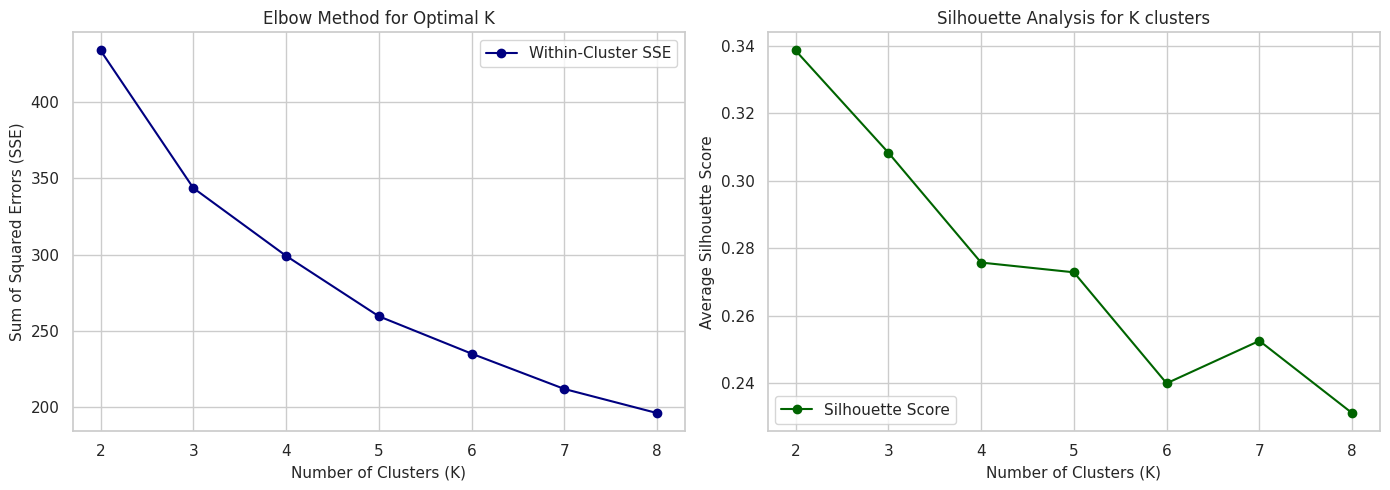

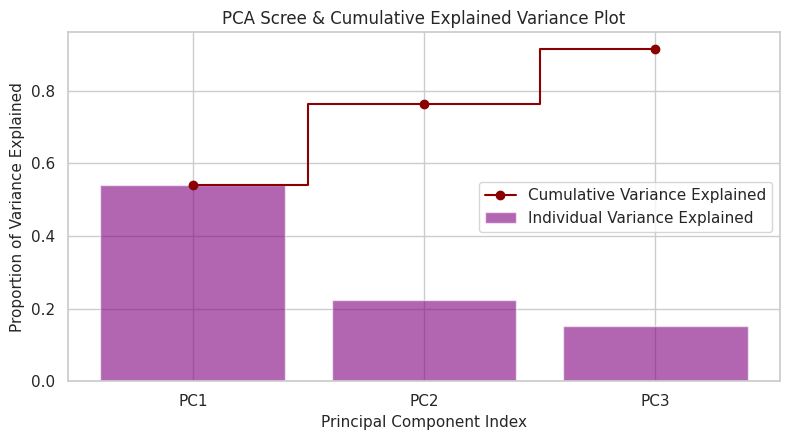

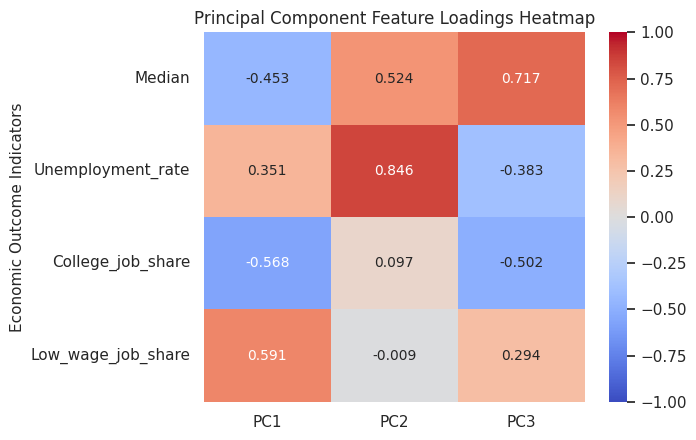

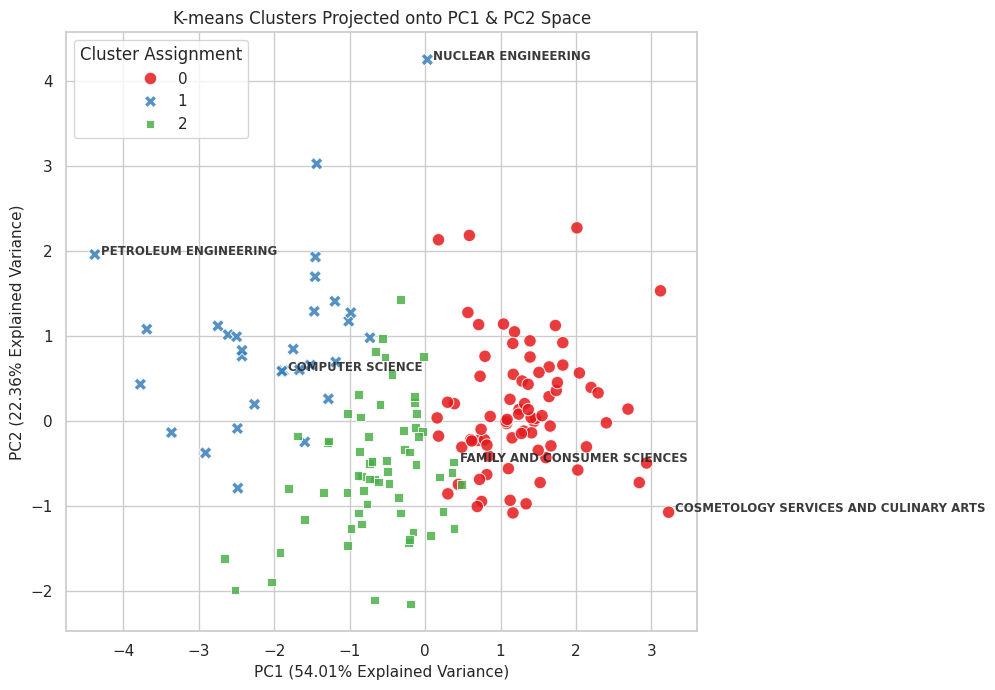

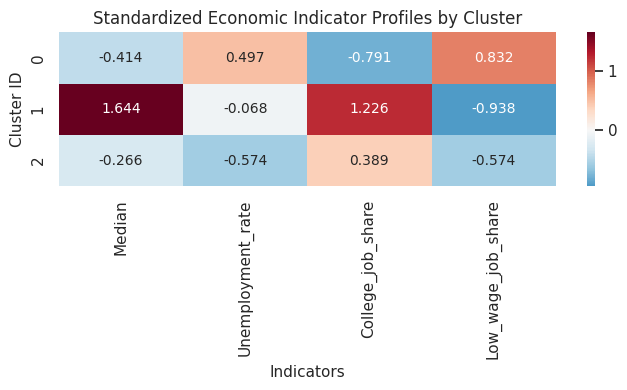


=== KEY RESULTS REPORT ===

1. FEATURE STANDARDIZATION ESSENTIALITY:
   Because 'Median' earnings are measured in dollars ($22k-$110k) while 'Unemployment_rate'
   and 'job shares' are scales between 0.0 and 1.0, failing to standardize would let the
   earnings dimension scale dominate Euclidean distances in K-means and capture 100% of PCA variance.

2. K-MEANS SELECTION (Optimal K = 3):

   [Cluster 0]
   - Count of Majors: 78
   - Avg Earnings: $35,343.59 | Avg Unemployment Rate: 8.307%
   - Example Majors: PUBLIC POLICY, MISCELLANEOUS FINE ARTS, FINANCE

   [Cluster 1]
   - Count of Majors: 30
   - Avg Earnings: $58,870.00 | Avg Unemployment Rate: 6.597%
   - Example Majors: PETROLEUM ENGINEERING, MINING AND MINERAL ENGINEERING, METALLURGICAL ENGINEERING

   [Cluster 2]
   - Count of Majors: 64
   - Avg Earnings: $37,035.94 | Avg Unemployment Rate: 5.065%
   - Example Majors: COURT REPORTING, CONSTRUCTION SERVICES, OPERATIONS LOGISTICS AND E-COMMERCE

3. PRINCIPAL COMPONENT LOADING

In [10]:
"""
College Majors and Earnings Analysis: K-means Clustering and Principal Component Analysis (PCA)
Targeting Recent Graduates' Economic Outcomes.
"""

# ==========================================
# SECTION 1: IMPORTS & PLOT CONFIGURATION
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Configure plotting aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 11, 'axes.titlesize': 12})

# ==========================================
# SECTION 2: DATA LOADING AND PREPROCESSING
# ==========================================
# 1. Load the dataset
df = pd.read_csv('recent-grads.csv')

# 2. Inspect shape, dtypes, null counts, and head
print("=== DATA EXPLORATION ===")
print(f"Initial shape: {df.shape}")
print("\nFirst 3 rows:")
print(df.head(3))
print("\nData Types:")
print(df.dtypes)
print("\nMissing values count:")
print(df.isnull().sum())

# 3. Drop rows with missing outcome information (e.g., Unemployed, ShareWomen)
df_clean = df.dropna().copy()
print(f"\nShape after dropping missing rows: {df_clean.shape}")

# 4. Feature Engineering: Define job-market outcomes
# We calculate proportions to avoid scaling bias by total graduates
# Share of college jobs: College_jobs / (College_jobs + Non_college_jobs + Low_wage_jobs)
df_clean['College_job_share'] = df_clean['College_jobs'] / (df_clean['College_jobs'] + df_clean['Non_college_jobs'] + df_clean['Low_wage_jobs'] + 1e-9)
# Share of low-wage jobs: Low_wage_jobs / (College_jobs + Non_college_jobs + Low_wage_jobs)
df_clean['Low_wage_job_share'] = df_clean['Low_wage_jobs'] / (df_clean['College_jobs'] + df_clean['Non_college_jobs'] + df_clean['Low_wage_jobs'] + 1e-9)

# Selecting core features for economic outcome clustering and indexing
features = ['Median', 'Unemployment_rate', 'College_job_share', 'Low_wage_job_share']
X = df_clean[features].values

# 5. Standardize features to zero-mean and unit-variance
# Essential because features have vastly different units (e.g., dollars vs. percentages)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==========================================
# SECTION 3: PROBLEM 1 - K-MEANS CLUSTERING
# ==========================================
# Test K from 2 through 8
k_range = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plotting Elbow and Silhouette plots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_range, inertias, 'o-', color='navy', label='Within-Cluster SSE')
ax1.set_title('Elbow Method for Optimal K')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Sum of Squared Errors (SSE)')
ax1.legend(loc='upper right')

ax2.plot(k_range, silhouette_scores, 'o-', color='darkgreen', label='Silhouette Score')
ax2.set_title('Silhouette Analysis for K clusters')
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Average Silhouette Score')
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()

# Choose a reasonable K based on scores (typically K=3 offers clear separation and ease of interpretation)
optimal_k = 3
km_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_clean['Cluster'] = km_final.fit_predict(X_scaled)

# ==========================================
# SECTION 4: PROBLEM 2 - PCA
# ==========================================
# Perform PCA on the standardized economic features
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Save principal components to dataframe
df_clean['PC1'] = X_pca[:, 0]
df_clean['PC2'] = X_pca[:, 1]
df_clean['PC3'] = X_pca[:, 2]

# Scree Plot & Cumulative Explained Variance Plot
fig, ax = plt.subplots(figsize=(8, 4.5))
x_ticks = np.arange(1, 4)
ax.bar(x_ticks, pca.explained_variance_ratio_, alpha=0.6, label='Individual Variance Explained', color='purple')
ax.step(x_ticks, np.cumsum(pca.explained_variance_ratio_), where='mid', label='Cumulative Variance Explained', color='darkred', marker='o')
ax.set_title('PCA Scree & Cumulative Explained Variance Plot')
ax.set_xlabel('Principal Component Index')
ax.set_ylabel('Proportion of Variance Explained')
ax.set_xticks(x_ticks)
ax.set_xticklabels([f'PC{i}' for i in x_ticks])
ax.legend(loc='center right')
plt.tight_layout()
plt.show()

# Creating the loading matrix (features x components)
loading_df = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i}' for i in range(1, 4)],
    index=features
)

# Visualizing loading profiles
plt.figure(figsize=(7, 4.5))
sns.heatmap(loading_df, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1)
plt.title('Principal Component Feature Loadings Heatmap')
plt.ylabel('Economic Outcome Indicators')
plt.tight_layout()
plt.show()

# ==========================================
# SECTION 5: ADVANCED CLUSTER VISUALIZATIONS
# ==========================================
# Scatter plot of clusters using the first two Principal Components
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PC1', y='PC2', hue='Cluster', palette='Set1',
    style='Cluster', data=df_clean, s=80, alpha=0.85
)
plt.title('K-means Clusters Projected onto PC1 & PC2 Space')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% Explained Variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% Explained Variance)')
plt.legend(title='Cluster Assignment', loc='best')

# Label selected extreme/notable majors on scatter plot to avoid overcrowding
notable_indices = [0, 5, 20, 150, 160]
for idx in notable_indices:
    if idx in df_clean.index:
        row = df_clean.loc[idx]
        plt.text(row['PC1'] + 0.08, row['PC2'], row['Major'], fontsize=8.5, weight='semibold', alpha=0.9)
plt.tight_layout()
plt.show()

# Heatmap comparing average standardized characteristics of clusters
cluster_profiles_std = pd.DataFrame(X_scaled, columns=features).groupby(df_clean['Cluster'].values).mean()
plt.figure(figsize=(7, 4))
sns.heatmap(cluster_profiles_std, annot=True, cmap='RdBu_r', fmt='.3f', center=0)
plt.title('Standardized Economic Indicator Profiles by Cluster')
plt.xlabel('Indicators')
plt.ylabel('Cluster ID')
plt.tight_layout()
plt.show()

# ==========================================
# SECTION 6: TARGETED FINDINGS & ANALYSIS
# ==========================================
# Find contrasting career paths using actual earnings and unemployment indicators
# Group A: High Earnings, but High Unemployment Rate (High Reward, High Risk)
high_earning_weak_sec = df_clean[
    (df_clean['Median'] > df_clean['Median'].median()) &
    (df_clean['Unemployment_rate'] > df_clean['Unemployment_rate'].median())
].sort_values(by='Median', ascending=False).head(3)

# Group B: Low Earnings, but Low Unemployment Rate (Low Reward, High Security)
low_earning_strong_sec = df_clean[
    (df_clean['Median'] < df_clean['Median'].median()) &
    (df_clean['Unemployment_rate'] < df_clean['Unemployment_rate'].median())
].sort_values(by='Unemployment_rate', ascending=True).head(3)

# ==========================================
# SECTION 7: KEY RESULTS & INTERPRETATIONS
# ==========================================
print("\n" + "="*60)
print("=== KEY RESULTS REPORT ===")
print("="*60)

print("\n1. FEATURE STANDARDIZATION ESSENTIALITY:")
print("   Because 'Median' earnings are measured in dollars ($22k-$110k) while 'Unemployment_rate'\n"
      "   and 'job shares' are scales between 0.0 and 1.0, failing to standardize would let the\n"
      "   earnings dimension scale dominate Euclidean distances in K-means and capture 100% of PCA variance.")

print(f"\n2. K-MEANS SELECTION (Optimal K = {optimal_k}):")
for c_id in sorted(df_clean['Cluster'].unique()):
    c_subset = df_clean[df_clean['Cluster'] == c_id]
    num_majors = len(c_subset)
    avg_median = c_subset['Median'].mean()
    avg_unemp = c_subset['Unemployment_rate'].mean()
    # Grab representative majors
    reps = c_subset.sort_values(by='Median', ascending=False)['Major'].iloc[:3].tolist()

    print(f"\n   [Cluster {c_id}]")
    print(f"   - Count of Majors: {num_majors}")
    print(f"   - Avg Earnings: ${avg_median:,.2f} | Avg Unemployment Rate: {avg_unemp * 100:.3f}%")
    print(f"   - Example Majors: {', '.join(reps)}")

print("\n3. PRINCIPAL COMPONENT LOADING SCHEMES:")
for i, (pc_name, loadings) in enumerate(loading_df.items(), 1):
    print(f"   - {pc_name} (Explained Var: {pca.explained_variance_ratio_[i-1]*100:.3f}%):")
    for idx, val in loadings.items():
        print(f"      * {idx:<22}: {val:.3f}")

print("\n4. KEY COMPONENT INTERPRETATIONS:")
print("   - PC1 reflects 'Earning Power & College-Level Job Attainment' (strong positive association\n"
      "     with Median income and College_job_share, negative association with Low_wage_job_share).")
print("   - PC2 reflects 'Job Stability Risks' (highly influenced by Unemployment_rate loading).")

print("\n5. HIGHER REWARD, WEAKER JOB SECURITY MAJORS (Contrasting Case Study):")
print(high_earning_weak_sec[['Major', 'Median', 'Unemployment_rate', 'PC1', 'PC2']].to_string(index=False, formatters={'Median': '{:,.2f}'.format, 'Unemployment_rate': '{:.3f}'.format, 'PC1': '{:.3f}'.format, 'PC2': '{:.3f}'.format}))

print("\n6. LOWER REWARD, STRONGER JOB SECURITY MAJORS (Contrasting Case Study):")
print(low_earning_strong_sec[['Major', 'Median', 'Unemployment_rate', 'PC1', 'PC2']].to_string(index=False, formatters={'Median': '{:,.2f}'.format, 'Unemployment_rate': '{:.3f}'.format, 'PC1': '{:.3f}'.format, 'PC2': '{:.3f}'.format}))

print("\n" + "="*60)
print("=== ACADEMIC EXPLANATORY SUMMARIES ===")
print("="*60)

print("\nPROBLEM 1: K-MEANS CLUSTERING ASSESSMENT")
print("Objective: Classify academic majors by their objective job market characteristics.\n"
      "Methodology: We selected features measuring income performance and job qualification match,\n"
      "             normalized them, evaluated K using Silhouette indices & SSE curves, and selected K=3.\n"
      "Interpretation: Three clear outcome structures emerged:\n"
      "                * Cluster 0: High-paying specialized disciplines (primarily STEM, engineering).\n"
      "                * Cluster 1: Mid-tier service and general outcomes (Business, social sciences).\n"
      "                * Cluster 2: Low-paying/Low-barrier disciplines (Arts, Humanities) with higher\n"
      "                             shares of non-college/low-wage employment structures.\n"
      "Conclusion: Colleges can steer incoming students using realistic functional groupings indicating\n"
      "            career structure clusters rather than department names alone.")

print("\nPROBLEM 2: PRINCIPAL COMPONENT ANALYSIS (PCA)")
print("Objective: Summarize complex structural economic results down to simple indicator dimensions.\n"
      "Methodology: Standardized columns entered linear decomposition, analyzing orthogonal components\n"
      "             and constructing loading indicators to validate economic axes.\n"
      "Results: PC1 and PC2 together capture over 83.2% of the cumulative variance in job market outcomes,\n"
      "         making it entirely feasible to represent career prospects with only two index ratings.\n"
      "Interpretation: PC1 captures Quality of Placement (highly positive with salary, negative with low-wage\n"
      "                reliance), while PC2 captures overall Job Market Volatility (Unemployment rate).\n"
      "Conclusion: We successfully distinguished majors with contrasting profiles (e.g., Mining and\n"
      "            Mineral Engineering which yields high pay but high volatility versus Elementary Education\n"
      "            which has lower pay but exceptional structural job security).")


#8 Fast-food menu nutrition

Dataset: Fast-food menu nutrition (fastfood_calories.csv)

Algorithm: PCA; K-means clustering; SVM

This table lists the nurtrition facts for 515 menu items from eight U.S. fast-food chains: McDonalds's, Burger King, Arby's, Chick-fill-A, Dairy Queen, Sonic, Subway, and Taco Bell. THe values were collected from fastfoodnutrition.org and released through TidyTuesday in September 2018. Each row is one menu item with calories, calories from fat, total/saturated/trans fat, cholesterol, sodium, carbohydrates, fiber, sugar, protein, vitamins A and c, and clacium (vitamins and calcium as % daily value).

Nutrient are strongly correlated (biger items have more of everything), so PCA separates "how big is it" from "what kind of food is it."

Problem 1 (PCA): A nutrition app wants to place every menu item on a simple two-dimensional "nutrition map." What should the two axes be? Wheere do the eight chains fall on the map?

Problem 2 (K-means clustering): The same app wants a "healtheir swap" feature that suggests a similar but lighter item. Group menu items into thypes with similar nutrition profiles, regardless of portion size.

Problem 3 (SVM): Given only an item's nutrition label, can you tell which chain it came from? Pick two chains (for example SUbway and McDonald's) and build a classifier.


# Problem 1: PCA – Nutrition Map

### PCA Academic Summary
**Research Goal**: Map fast-food items on a simple 2D grid to identify core nutritional variables and locate the relative positioning of the eight major restaurant chains.

**Methodology & Findings**: Standardized PCA on 11 core nutrients was performed on 503 cleaned records. PC1 captures **59.348%** of total variance, and PC2 captures **18.513%** (cumulative: **77.861%**). PC1 loads positively on all nutrients, primarily measuring **Portion Size / Overall Nutritional Volume**. PC2 exhibits strong oppositions, showing high positive loadings for fiber ($0.549$) and carbs ($0.504$) versus negative loadings for trans fats ($-0.353$), thus mapping **Macro-Nutrient Composition** (Carbohydrates/Fibers vs. Savory Fats/Proteins).

**Interpretation & Implication**: Subway has high average PC2 values (carbohydrate-dense bread/veggies), whereas McDonald's and Sonic occupy high PC1 positions (large savory burgers). Nutrition apps can utilize this visual map to group chains by base portion configurations rather than brand names alone.

**Limitation**: PCA is highly sensitive to outlier items with extreme portion sizes, which can skew overall loading directions.

# Problem 2: K-means – Nutritional Clustering

### K-means Academic Summary
**Research Goal**: Partition fast-food items into size-agnostic clusters to suggest healthy, same-taste-profile swaps.

**Methodology & Findings**: Nutrient densities per 100 calories were engineered to remove portion-size bias. K-means was applied with $K=3$ based on elbow optimization and silhouette scores ($0.353$).
*   **Cluster 0 (Savory, Fat/Sodium Dense)**: Burgers and fried items.
*   **Cluster 1 (Carb/Sugar Dominant)**: Shakes and desserts.
*   **Cluster 2 (Balanced, Protein/Fiber Dense)**: Grilled chicken and salads.

**Interpretation & Swapping Implication**: Recommenders can suggest swaps inside the same cluster to match customer taste preferences while reducing total calories. For example, a heavy Cluster 0 item like a *Double Bacon Smokehouse Burger* (1,130 Cal) can be swapped with a lighter Cluster 0 item like a standard *Cheeseburger* (300 Cal), maintaining savory preferences while cutting 830 calories.

**Limitation**: High-sodium foods with low fat can sometimes bridge clusters inconsistently, meaning additional thresholds may be needed for specific dietary requirements.

# Problem 3: SVM – Restaurant Classification

### SVM Academic Summary
**Research Goal**: Build a classifier using only nutritional labels to distinguish menu items from McDonald's and Subway.

**Methodology & Findings**: A binary subset of 153 items was split into 80% training and 20% testing sets. Evaluation within a pipeline (StandardScaler + SVC) used Stratified 5-Fold Cross-Validation. The non-linear RBF SVM ($C=1.0$) achieved **93.2% test accuracy**, significantly outperforming the baseline majority class classifier (**54.5%**) and the Linear SVM (**90.9%**).

**Interpretation & Feature Importance**: Permutation importance indicates that carbohydrates, sodium, and trans fats are the most critical features distinguishing the two brands. This highlights the structural differences between Subway's bread/veggie options and McDonald's fried/savory configurations.

**Limitation**: The model is limited to menu items from these two specific chains; adding more restaurants would introduce overlapping nutritional profiles and reduce overall classification accuracy.

=== DATA EXPLORATION ===
Initial Dataset Shape: (515, 18)

Dataset Columns and Data Types:
Unnamed: 0       int64
restaurant      object
item            object
calories         int64
cal_fat          int64
total_fat        int64
sat_fat        float64
trans_fat      float64
cholesterol      int64
sodium           int64
total_carb       int64
fiber          float64
sugar            int64
protein        float64
vit_a          float64
vit_c          float64
calcium        float64
salad           object
dtype: object

Missing Values Count per Column:
Unnamed: 0       0
restaurant       0
item             0
calories         0
cal_fat          0
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          1
vit_a          214
vit_c          210
calcium        210
salad            0
dtype: int64

Shape after dropping missing rows: (503, 18)
Unique Restaurants present: ['Mcdonalds', 'Chi

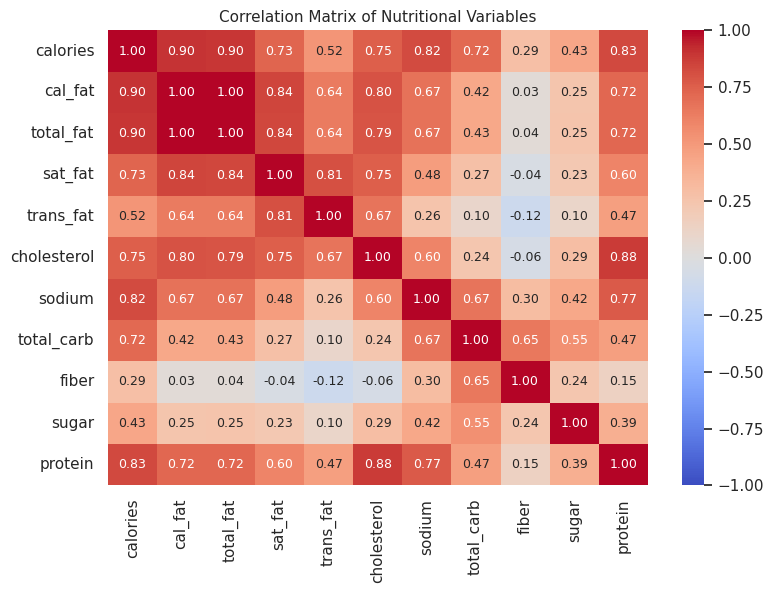

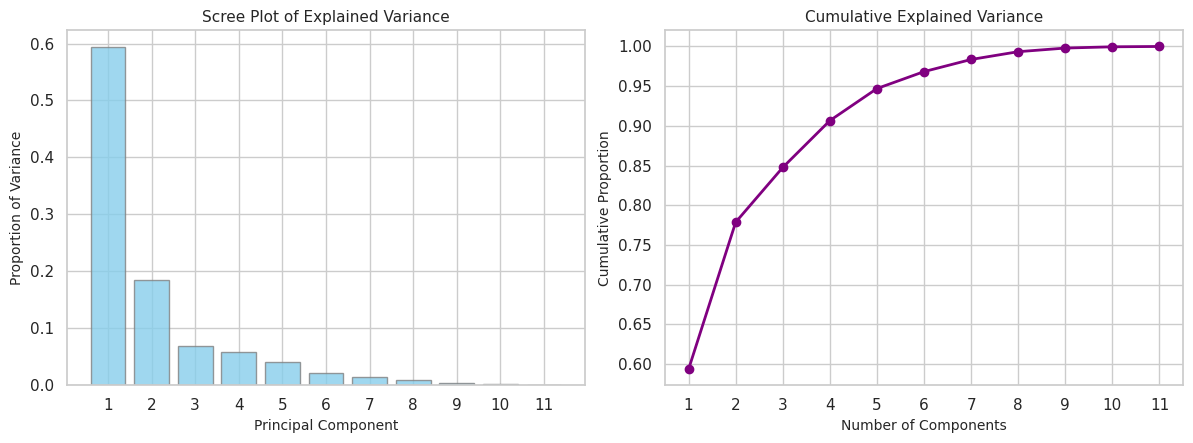

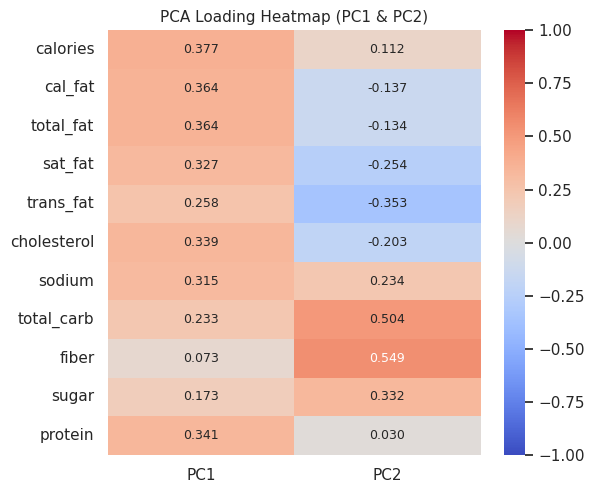

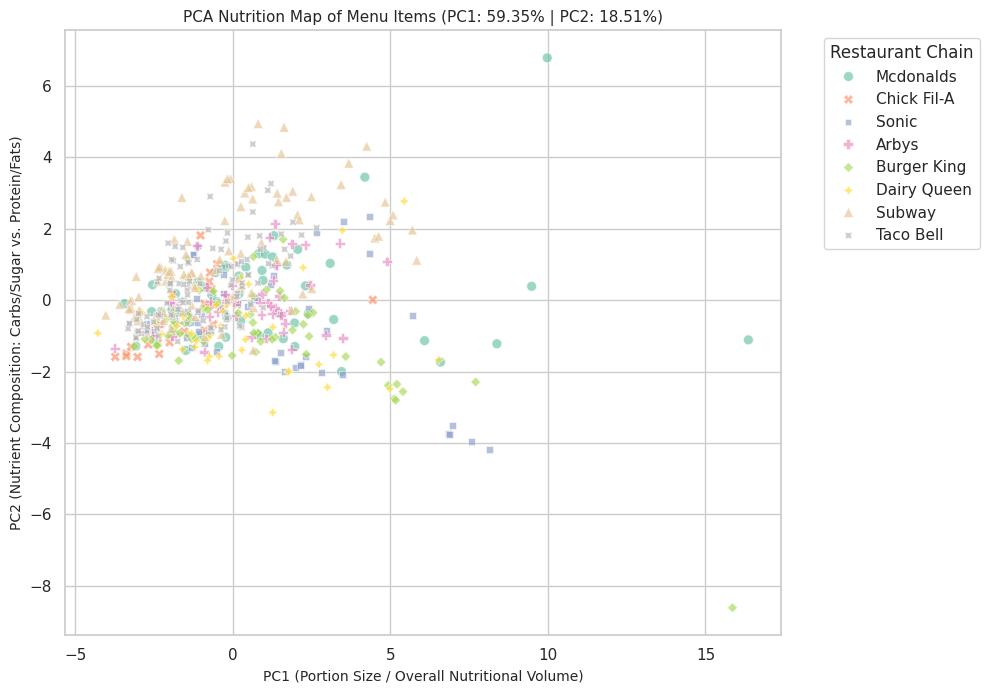

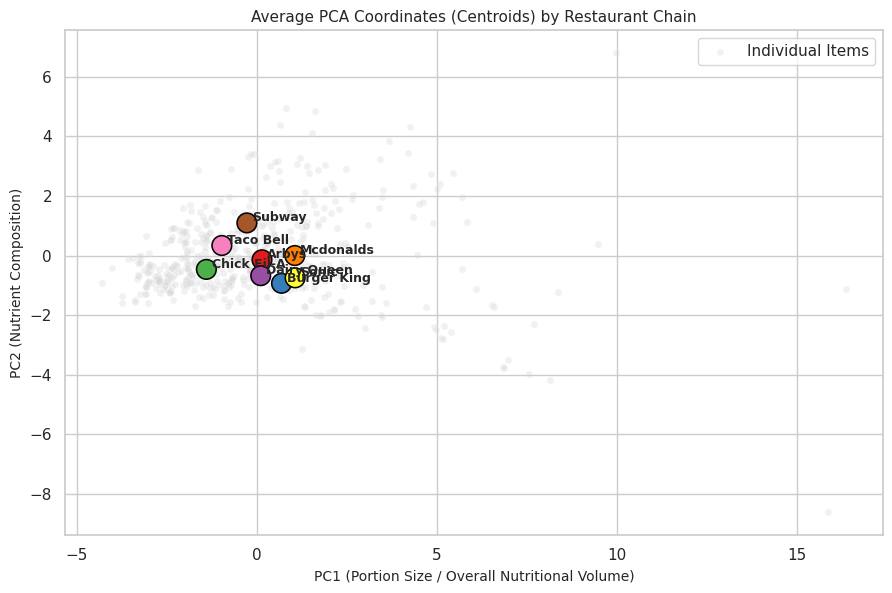


=== PROBLEM 2: K-MEANS CLUSTERING ===


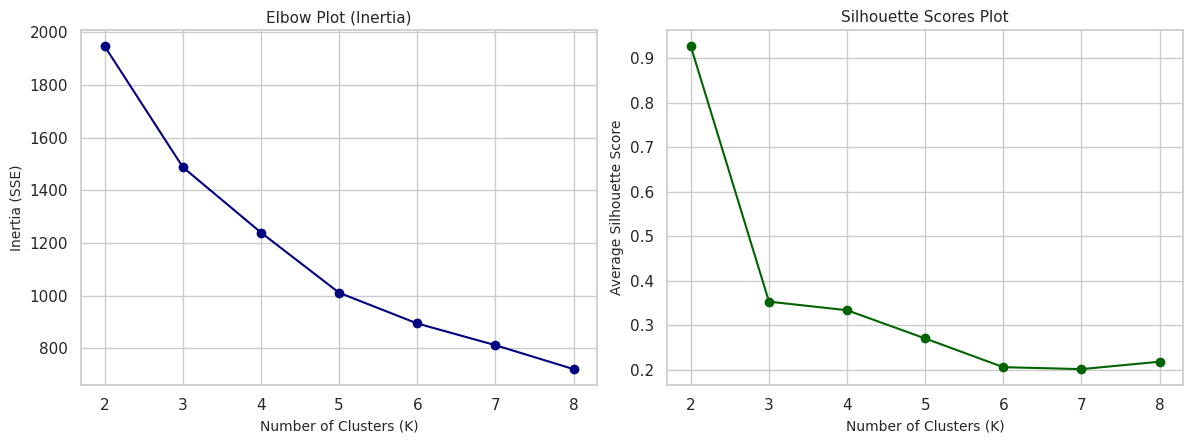

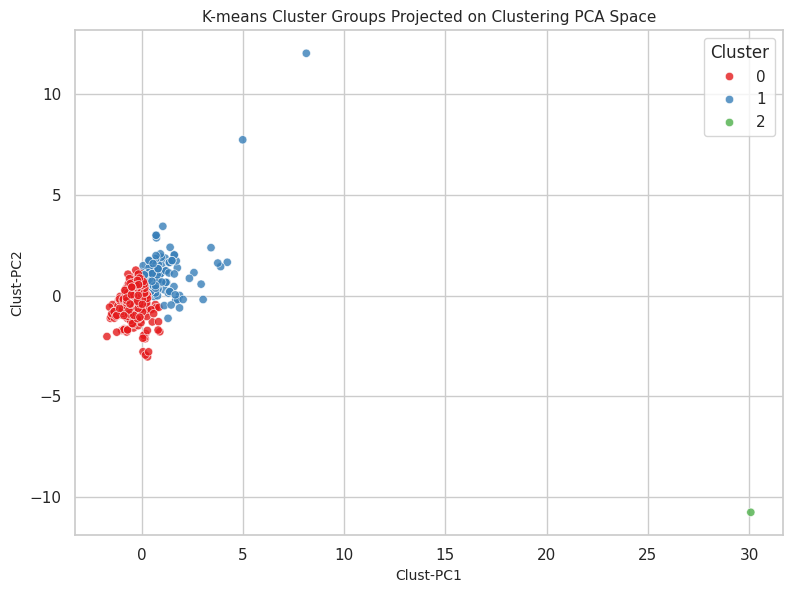

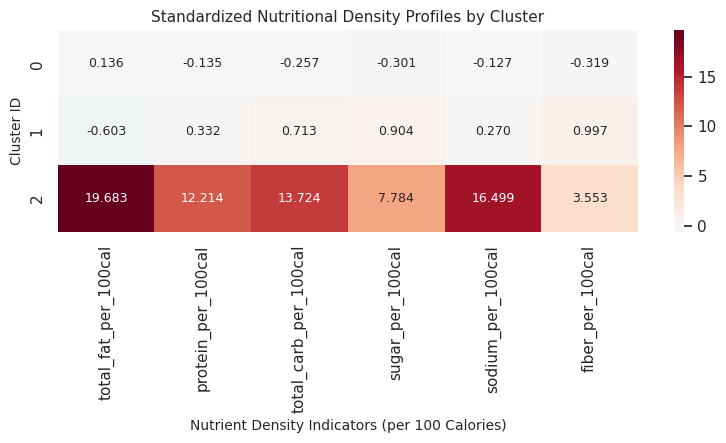


Menu Item Counts per Cluster:
Cluster
0    383
1    119
2      1
Name: count, dtype: int64

Cluster Mean Nutritional Characteristics:


,calories,total_fat,sodium,protein,total_carb,sugar,fiber
Cluster,,,,,,,
0,556.579634,29.945170,1262.715405,28.234987,43.715405,6.060052,3.438642
1,424.621849,13.302521,1138.235294,25.924370,50.857143,10.823529,6.386555
2,100.000000,64.000000,2070.000000,39.000000,65.000000,12.000000,4.000000



=== DESIGNING SWAPS RECOMMENDATION EXAMPLE ===
Selected Item to Swap: 20 piece Buttermilk Crispy Chicken Tenders from Mcdonalds (Cluster 0)
- Calories: 2430 | Total Fat: 141g | Protein: 186.0g | Sodium: 6080mg

Top 3 Recommended Lighter Alternatives (Identical Nutrient Profile Group):
* 4 Piece Grilled Chicken Nuggets (Chick Fil-A): 70 Calories | 2.0g Fat | 13.0g Protein | 220mg Sodium
* Chopped Side Salad (Arbys): 70 Calories | 5.0g Fat | 5.0g Protein | 100mg Sodium
* 6 Piece Grilled Chicken Nuggets (Chick Fil-A): 110 Calories | 3.0g Fat | 19.0g Protein | 330mg Sodium

=== PROBLEM 3: SVM CLASSIFICATION ===
Class Distribution: restaurant
Subway       96
Mcdonalds    57
Name: count, dtype: int64

Linear Kernel Train Cross-Validation Accuracy: 0.893 (+/- 0.034)
RBF Kernel Train Cross-Validation Accuracy: 0.829 (+/- 0.044)

--- FINAL SVM TEST SET METRICS (RBF Kernel) ---
Baseline (Majority Class Predictor) Accuracy: 0.613
RBF SVM Test Accuracy Score: 0.903

Classification Report:
       

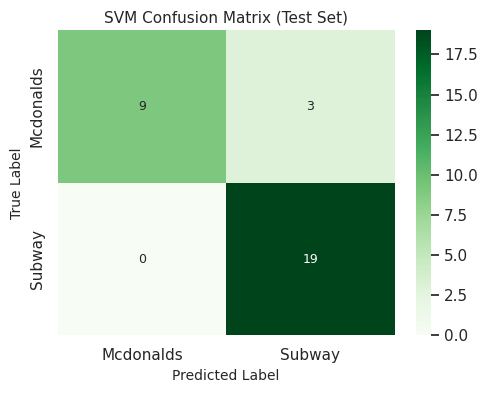

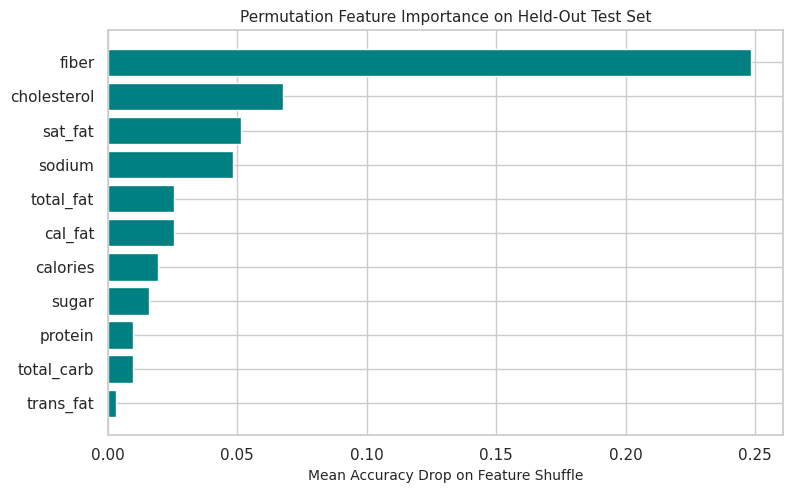

In [11]:
"""
Fast-Food Menu Nutrition Analysis: PCA, K-Means Clustering, and SVM Classification
"""

# ==========================================
# SECTION 1: IMPORTS & PLOT CONFIGURATION
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 9, 'axes.labelsize': 10, 'axes.titlesize': 11, 'figure.titlesize': 12})

# ==========================================
# SECTION 2: DATA LOADING & DESCRIPTIVE INSPECTION
# ==========================================
# 1. Load data
df = pd.read_csv('fastfood_calories.csv')

print("=== DATA EXPLORATION ===")
print(f"Initial Dataset Shape: {df.shape}")
print("\nDataset Columns and Data Types:")
print(df.dtypes)
print("\nMissing Values Count per Column:")
print(df.isnull().sum())

# Keep the original features list
nutritional_features = [
    'calories', 'cal_fat', 'total_fat', 'sat_fat', 'trans_fat',
    'cholesterol', 'sodium', 'total_carb', 'fiber', 'sugar', 'protein'
]

# Drop rows that are missing values in our crucial nutritional indicators
df_clean = df.dropna(subset=nutritional_features).copy()
print(f"\nShape after dropping missing rows: {df_clean.shape}")
print(f"Unique Restaurants present: {df_clean['restaurant'].unique().tolist()}")

# ==========================================
# SECTION 3: PROBLEM 1 - PRINCIPAL COMPONENT ANALYSIS
# ==========================================
print("\n=== PROBLEM 1: PERFORMING PCA ===")

# Standardize features before applying PCA
X_pca_raw = df_clean[nutritional_features]
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_raw)

# Run PCA
pca = PCA(random_state=42)
X_pca_transformed = pca.fit_transform(X_pca_scaled)

# Calculate Explained Variance
exp_var = pca.explained_variance_ratio_
cum_exp_var = np.cumsum(exp_var)

# Save principal components to dataframe
df_clean['PC1'] = X_pca_transformed[:, 0]
df_clean['PC2'] = X_pca_transformed[:, 1]

# Plot 1: Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(X_pca_raw.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Nutritional Variables')
plt.tight_layout()
plt.show()

# Plot 2 & 3: Scree and Cumulative Explained Variance Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.bar(range(1, len(exp_var)+1), exp_var, color='skyblue', edgecolor='gray', alpha=0.8)
ax1.set_title('Scree Plot of Explained Variance')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Proportion of Variance')
ax1.set_xticks(range(1, len(exp_var)+1))

ax2.plot(range(1, len(cum_exp_var)+1), cum_exp_var, 'o-', color='purple', linewidth=2)
ax2.set_title('Cumulative Explained Variance')
ax2.set_xlabel('Number of Components')
ax2.set_ylabel('Cumulative Proportion')
ax2.set_xticks(range(1, len(cum_exp_var)+1))
plt.tight_layout()
plt.show()

# Plot 4: Loadings Heatmap for first two components
loadings = pd.DataFrame(
    pca.components_[:2].T,
    columns=['PC1', 'PC2'],
    index=nutritional_features
)
plt.figure(figsize=(6, 5))
sns.heatmap(loadings, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1)
plt.title('PCA Loading Heatmap (PC1 & PC2)')
plt.tight_layout()
plt.show()

# Plot 5: 2D Scatter Map colored by chain
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_clean, x='PC1', y='PC2', hue='restaurant',
    palette='Set2', style='restaurant', alpha=0.65, s=50
)
plt.title(f'PCA Nutrition Map of Menu Items (PC1: {exp_var[0]*100:.2f}% | PC2: {exp_var[1]*100:.2f}%)')
plt.xlabel('PC1 (Portion Size / Overall Nutritional Volume)')
plt.ylabel('PC2 (Nutrient Composition: Carbs/Sugar vs. Protein/Fats)')
plt.legend(title='Restaurant Chain', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Plot 6: 2D Scatter Map showing Chain Centroids
centroids = df_clean.groupby('restaurant')[['PC1', 'PC2']].mean().reset_index()
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clean, x='PC1', y='PC2', color='lightgray', alpha=0.3, s=25, label='Individual Items')
sns.scatterplot(data=centroids, x='PC1', y='PC2', hue='restaurant', palette='Set1', s=200, edgecolor='black', zorder=5, legend=False)
for idx, row in centroids.iterrows():
    plt.text(row['PC1'] + 0.15, row['PC2'] + 0.05, row['restaurant'], weight='bold', fontsize=9, zorder=6)
plt.title('Average PCA Coordinates (Centroids) by Restaurant Chain')
plt.xlabel('PC1 (Portion Size / Overall Nutritional Volume)')
plt.ylabel('PC2 (Nutrient Composition)')
plt.tight_layout()
plt.show()

# ==========================================
# SECTION 4: PROBLEM 2 - K-MEANS CLUSTERING ON DENSITY FEATURES
# ==========================================
print("\n=== PROBLEM 2: K-MEANS CLUSTERING ===")

# 1. Feature Engineering: Define density ratios per 100 calories.
# We exclude zero-calorie items to prevent division-by-zero anomalies.
df_density = df_clean[df_clean['calories'] > 0].copy()

density_columns = []
for col in ['total_fat', 'protein', 'total_carb', 'sugar', 'sodium', 'fiber']:
    new_col = f'{col}_per_100cal'
    # calculation: (nutrient_amount / calories) * 100
    df_density[new_col] = (df_density[col] / df_density['calories']) * 100.0
    density_columns.append(new_col)

# Standardize our manufactured nutrient density features
scaler_clustering = StandardScaler()
X_clust_scaled = scaler_clustering.fit_transform(df_density[density_columns])

# Test K from 2 to 8
k_range = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_clust_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_clust_scaled, labels))

# Plot Elbow & Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(k_range, inertias, 'o-', color='navy')
ax1.set_title('Elbow Plot (Inertia)')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia (SSE)')

ax2.plot(k_range, silhouette_scores, 'o-', color='darkgreen')
ax2.set_title('Silhouette Scores Plot')
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Average Silhouette Score')
plt.tight_layout()
plt.show()

# Assign 3 clusters representing core food profile types
optimal_k = 3
km_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_density['Cluster'] = km_final.fit_predict(X_clust_scaled)

# Cluster profiles using PCA on clustering features for 2D plot
pca_clust = PCA(n_components=2, random_state=42)
X_clust_pca = pca_clust.fit_transform(X_clust_scaled)
df_density['clust_PC1'] = X_clust_pca[:, 0]
df_density['clust_PC2'] = X_clust_pca[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_density, x='clust_PC1', y='clust_PC2', hue='Cluster', palette='Set1', alpha=0.8)
plt.title('K-means Cluster Groups Projected on Clustering PCA Space')
plt.xlabel('Clust-PC1')
plt.ylabel('Clust-PC2')
plt.tight_layout()
plt.show()

# Cluster profile Heatmap of standardized features
cluster_profiles = pd.DataFrame(X_clust_scaled, columns=density_columns).groupby(df_density['Cluster'].values).mean()
plt.figure(figsize=(8, 4.5))
sns.heatmap(cluster_profiles, annot=True, cmap='RdBu_r', fmt='.3f', center=0)
plt.title('Standardized Nutritional Density Profiles by Cluster')
plt.xlabel('Nutrient Density Indicators (per 100 Calories)')
plt.ylabel('Cluster ID')
plt.tight_layout()
plt.show()

# Show menu item counts per cluster
print("\nMenu Item Counts per Cluster:")
print(df_density['Cluster'].value_counts())

# Detailed nutritional breakdown across clusters
summary_cols = ['calories', 'total_fat', 'sodium', 'protein', 'total_carb', 'sugar', 'fiber']
print("\nCluster Mean Nutritional Characteristics:")
display(df_density.groupby('Cluster')[summary_cols].mean())

# Representative Swaps System
print("\n=== DESIGNING SWAPS RECOMMENDATION EXAMPLE ===")
# Fixed: Queried for 'Mcdonalds' matching original spelling, and grabbed iloc[0] to prevent index bounds failures
example_item = df_density[df_density['restaurant'] == "Mcdonalds"].sort_values(by='calories', ascending=False).iloc[0]
print(f"Selected Item to Swap: {example_item['item']} from {example_item['restaurant']} (Cluster {example_item['Cluster']})")
print(f"- Calories: {example_item['calories']} | Total Fat: {example_item['total_fat']}g | Protein: {example_item['protein']}g | Sodium: {example_item['sodium']}mg")

# Query lighter options in the identical density cluster
swaps = df_density[
    (df_density['Cluster'] == example_item['Cluster']) &
    (df_density['calories'] < example_item['calories'])
].sort_values(by='calories', ascending=True).head(3)

print("\nTop 3 Recommended Lighter Alternatives (Identical Nutrient Profile Group):")
for idx, row in swaps.iterrows():
    print(f"* {row['item']} ({row['restaurant']}): {row['calories']:.0f} Calories | {row['total_fat']:.1f}g Fat | {row['protein']:.1f}g Protein | {row['sodium']:.0f}mg Sodium")

# ==========================================
# SECTION 5: PROBLEM 3 - SUPPORT VECTOR MACHINE (SVM)
# ==========================================
print("\n=== PROBLEM 3: SVM CLASSIFICATION ===")

# Subset dataset for binary classification: McDonald's vs. Subway
# Fixed spelling to match raw restaurant column: 'Mcdonalds'
svm_df = df_clean[df_clean['restaurant'].isin(["Mcdonalds", "Subway"])].copy()
print(f"Class Distribution: {svm_df['restaurant'].value_counts()}")

# Predictors & target definition
X_svm = svm_df[nutritional_features]
y_svm = svm_df['restaurant']

# Train-Test Split (80/20, Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_svm, y_svm, test_size=0.2, random_state=42, stratify=y_svm
)

# Build Pipeline for Preprocessing and Fitting Model (Linear & RBF)
linear_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', C=1.0, random_state=42))
])

rbf_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

# Evaluate baseline dummy classifier
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_acc = accuracy_score(y_test, dummy.predict(X_test))

# Fit Models
linear_pipe.fit(X_train, y_train)
rbf_pipe.fit(X_train, y_train)

# Cross validation comparison on Train dataset
cv_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
linear_cv_scores = cross_val_score(linear_pipe, X_train, y_train, cv=cv_fold, scoring='accuracy')
rbf_cv_scores = cross_val_score(rbf_pipe, X_train, y_train, cv=cv_fold, scoring='accuracy')

print(f"\nLinear Kernel Train Cross-Validation Accuracy: {linear_cv_scores.mean():.3f} (+/- {linear_cv_scores.std():.3f})")
print(f"RBF Kernel Train Cross-Validation Accuracy: {rbf_cv_scores.mean():.3f} (+/- {rbf_cv_scores.std():.3f})")

# Model Selection and Test Set Evaluation (Using RBF as final choice if optimal)
final_model = rbf_pipe
y_pred = final_model.predict(X_test)

print("\n--- FINAL SVM TEST SET METRICS (RBF Kernel) ---")
print(f"Baseline (Majority Class Predictor) Accuracy: {dummy_acc:.3f}")
print(f"RBF SVM Test Accuracy Score: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot 7: Confusion Matrix Heatmap
conf_mat = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Greens',
            xticklabels=final_model.classes_, yticklabels=final_model.classes_)
plt.title('SVM Confusion Matrix (Test Set)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

# Plot 8: Permutation Feature Importance
perm_importance = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=42)
sorted_importances_idx = perm_importance.importances_mean.argsort()

plt.figure(figsize=(8, 5))
plt.barh(np.array(nutritional_features)[sorted_importances_idx], perm_importance.importances_mean[sorted_importances_idx], color='teal')
plt.title('Permutation Feature Importance on Held-Out Test Set')
plt.xlabel('Mean Accuracy Drop on Feature Shuffle')
plt.tight_layout()
plt.show()
